# 🚗 YOLO11 + SAM 2.1 | Vehicle Video Segmentation

Detect **cars, motorcycles, buses, and trucks** with YOLO11, then create pixel-level masks with SAM 2.1.

## 1. Install dependencies

In [1]:
!pip install -q -U ultralytics tqdm

## 2. Import libraries

In [2]:
import cv2
import numpy as np
import time
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
from ultralytics import YOLO, SAM
from google.colab import files
from IPython.display import Video, display

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 3. Upload a video

In [3]:
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("Please upload a video.")

VIDEO_PATH = next(iter(uploaded))
print("Uploaded:", VIDEO_PATH)

Saving 01.mp4 to 01.mp4
Uploaded: 01.mp4


## 4. Read video information

In [4]:
def get_video_info(path):
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError("Could not open video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    cap.release()

    return fps, width, height, frames


# Get video information.
fps, width, height, frames = get_video_info(VIDEO_PATH)

print("FPS:", fps)
print("Size:", width, "x", height)
print("Frames:", frames)
print("Duration:", round(frames / fps, 2), "seconds")

FPS: 60.0
Size: 1920 x 1080
Frames: 600
Duration: 10.0 seconds


## 5. Load YOLO11 and SAM 2.1

In [5]:
yolo_model = YOLO("yolo11n.pt")
sam_model = SAM("sam2.1_b.pt")

print("Models loaded successfully!")

Models loaded successfully!


## 6. Select vehicle classes


In [6]:
VEHICLE_CLASSES = {
    2: "Car",
    3: "Motorcycle",
    5: "Bus",
    7: "Truck"
}

VEHICLE_CLASS_IDS = list(VEHICLE_CLASSES)
CONFIDENCE = 0.25

# BGR colors for each vehicle class.
CLASS_COLORS = {
    2: (255, 0, 0),      # Car: blue
    3: (0, 0, 255),      # Motorcycle: red
    5: (0, 255, 255),   # Bus: yellow
    7: (255, 255, 0)    # Truck: cyan
}

print("Selected classes:", VEHICLE_CLASS_IDS)

Selected classes: [2, 3, 5, 7]


## 7. Create one reusable detection and segmentation function

In [7]:
def process_frame(frame):

    # Detect vehicles using YOLO.
    result = yolo_model(frame, classes=VEHICLE_CLASS_IDS, conf=CONFIDENCE, verbose=False)[0]

    # Return the original frame if no vehicles are detected.
    if result.boxes is None or len(result.boxes) == 0:
        return frame.copy()

    # Get bounding box coordinates.
    boxes = result.boxes.xyxy.cpu().numpy()

    # Get detected vehicle class IDs.
    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    # Get detection confidence scores.
    confidences = result.boxes.conf.cpu().numpy()

    # Use YOLO bounding boxes to generate segmentation masks with SAM.
    sam_result = sam_model(frame, bboxes=boxes.tolist(), verbose=False)[0]

    # Return the original frame if SAM does not generate masks.
    if sam_result.masks is None:
        return frame.copy()

    # Get segmentation masks as NumPy arrays.
    masks = sam_result.masks.data.cpu().numpy()

    # Create a copy of the frame for drawing.
    output = frame.copy()

    # Get the frame height and width.
    height, width = frame.shape[:2]

    # Process each detected vehicle and its corresponding mask.
    for mask, box, class_id, confidence in zip(masks, boxes, class_ids, confidences):

        # Resize the mask to match the original frame size.
        mask = cv2.resize(mask.astype(np.uint8), (width, height)) > 0

        # Get the color assigned to the detected vehicle class.
        color = CLASS_COLORS[class_id]

        # Apply the color only inside the segmentation mask.
        output[mask] = (output[mask] * 0.5 + np.array(color) * 0.5).astype(np.uint8)

        # Get the bounding box coordinates as integers.
        x1, y1, x2, y2 = box.astype(int)

        # Create a label with the vehicle name and confidence score.
        label = f"{VEHICLE_CLASSES[class_id]} {confidence:.2f}"

        # Draw a bounding box around the detected vehicle.
        cv2.rectangle(output, (x1, y1), (x2, y2), color, 2)

        # Draw the vehicle label above the bounding box.
        cv2.putText(output, label, (x1, max(y1 - 10, 25)), cv2.FONT_HERSHEY_SIMPLEX, 0.65, color, 2)

    # ✅ Return the frame with segmentation masks and labels.
    return output

## 8. Test on the first frame

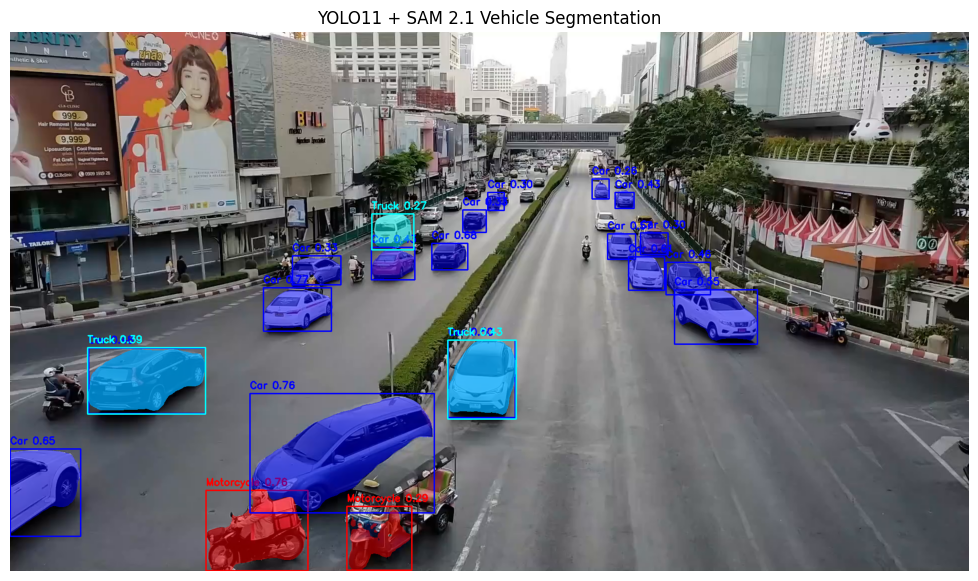

In [8]:
cap = cv2.VideoCapture(VIDEO_PATH)
ret, first_frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Could not read the first frame.")

preview = process_frame(first_frame)

plt.figure(figsize=(14, 7))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("YOLO11 + SAM 2.1 Vehicle Segmentation")
plt.axis("off")
plt.show()

## 9. Process the complete video

In [9]:
# Output video path.
OUTPUT_PATH = "yolo_sam2_vehicle_segmented_output.mp4"

# Open the input video.
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open the video.")

# Get video properties directly from the video capture object.
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Create the output video writer.
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(OUTPUT_PATH, fourcc, fps, (width, height))

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video.")

# Count processed frames.
frame_count = 0

# Read and process video frames.
with tqdm(total=total_frames, desc="Segmenting video") as progress:

    while True:

        # Read the next frame.
        ret, frame = cap.read()

        # Stop when no more frames are available.
        if not ret:
            break

        # Segment vehicles using YOLO and SAM.
        segmented_frame = process_frame(frame)

        # Save the segmented frame.
        writer.write(segmented_frame)

        # Update frame count and progress bar.
        frame_count += 1
        progress.update(1)

# Release video resources.
cap.release()
writer.release()

# Display completion information.
print("Segmentation completed!")
print("Processed frames:", frame_count)
print("Output:", OUTPUT_PATH)

Segmenting video:   0%|          | 0/600 [00:00<?, ?it/s]

Segmentation completed!
Processed frames: 600
Output: yolo_sam2_vehicle_segmented_output.mp4


## 10. Download the segmented video

In [10]:
files.download(OUTPUT_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>